# Phase 3 · Rhetorical Role Prediction

<div align="center">

## MODEL4 · Full Fine-Tuning

**Full-model adaptation**

`CS781 Capstone` &nbsp; · &nbsp; `Corporate Law + IT` &nbsp; · &nbsp; `Sentence classification`

</div>

---

### Experiment at a glance

| Item | Configuration |
|:--|:--|
| **Phase 1 backbone** | `model4(2).ipynb` |
| **Architecture** | RoPE, RMSNorm, sink/window attention, GQA and alternating bottleneck feed-forward layers |
| **Representation size** | 560-dimensional hidden states |
| **Adaptation method** | Full Fine-Tuning |
| **Checkpoint selection** | Development Macro-F1 |
| **Domains** | Corporate Law (CL) and Information Technology (IT) |

> **Objective**
>
> Updates the complete Phase 1 backbone together with the sentence-classification head. The model predicts exactly one rhetorical-role label per sentence while preserving document order.

### Before you run

1. Attach the **matching Phase 1 artifacts** as a Kaggle input dataset.
2. Set `ASSET_DIR` in the setup cell to that dataset's directory.
3. Confirm it contains `pytorch_model.bin` and `custom_bpe_scratch.json`.
4. Enable internet access and add a Kaggle Secret named `HF` containing a Hugging Face read token with access to `Exploration-Lab/CS-781-Capstone`.

> **Checkpoint safety:** Model 2 and Model 4 checkpoints/tokenizers are not interchangeable. This notebook uses the architecture and tokenizer implementation from its matching Phase 1 notebook; it does not use an external pretrained language model.

### Notebook workflow

`Setup` → `Tokenizer` → `Backbone` → `Data` → `Adaptation` → `Training & validation` → `Predictions`

---

**Run cells from top to bottom.** Training has not been executed in this environment, so no performance scores are claimed.


> **No Hugging Face token required:** attach the Phase-3 dataset JSON files as a Kaggle Input. The notebook reads them locally from `/kaggle/input`; it does not call the Hugging Face Hub. Also attach the matching Model 4 Phase-1 checkpoint and tokenizer files.


In [1]:
import json, os, random, math
from pathlib import Path
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt
from sklearn.metrics import f1_score, precision_score, recall_score, classification_report, confusion_matrix
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', DEVICE)
ASSET_DIR = Path('/kaggle/input/datasets/kalyanbabuk/phase1m4')
OUTPUT_DIR = Path('/kaggle/working/phase3_rr')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
VOCAB_SIZE = 32000
N_LAYER = 15
N_HEAD = 8
N_KV_HEAD = 4
MODEL_CONTEXT_LENGTH = 2048
MAX_LENGTH = 256
MAX_CONTEXT_TOKENS = 64
USE_PREVIOUS_SENTENCE_CONTEXT = True
BATCH_SIZE = 2
ACCUM_STEPS = 8
EPOCHS = 6
PATIENCE = 3
WARMUP_FRACTION = 0.06
MIN_LR_RATIO = 0.1
WEIGHT_DECAY = 0.01
DROPOUT = 0.15
GRAD_CLIP = 1.0
DOMAIN = 'both'

HF_DATASET_REPO = "Exploration-Lab/CS-781-Capstone"

# Authenticate with a Kaggle Secret named HF. Never paste a real token into a notebook.
def get_hf_token():
    token = os.environ.get("HF_TOKEN") or os.environ.get("HUGGING_FACE_HUB_TOKEN")
    if token:
        return token
    try:
        from kaggle_secrets import UserSecretsClient
        token = UserSecretsClient().get_secret("HF")
    except Exception:
        token = None
    if not token:
        from getpass import getpass
        token = getpass("Hugging Face token (input hidden): ").strip()
    if not token:
        raise RuntimeError(
            "A Hugging Face token is required. In Kaggle, add a secret named 'HF' "
            "containing your token and enable access to secrets for this notebook."
        )
    return token

HF_TOKEN = get_hf_token()
os.environ["HF_TOKEN"] = HF_TOKEN
from huggingface_hub import hf_hub_download
print("Hugging Face authentication configured for", HF_DATASET_REPO)

def locate_asset(filename):
    root = Path(ASSET_DIR)
    if not root.exists():
        raise FileNotFoundError(f'Attach the matching Phase-1 asset dataset and set ASSET_DIR. Missing: {root}')
    hits = list(root.rglob(filename))
    if not hits:
        raise FileNotFoundError(f'{filename} not found below {root}')
    if len(hits) > 1:
        print('Multiple matches; using', hits[0])
    return hits[0]

def fetch_json(path):
    """Download a Phase-3 JSON file from the private Hugging Face dataset repo."""
    try:
        local_path = hf_hub_download(
            repo_id=HF_DATASET_REPO,
            filename=path,
            repo_type="dataset",
            token=HF_TOKEN,
        )
    except Exception as exc:
        raise RuntimeError(
            f"Could not download {path} from {HF_DATASET_REPO}. Check that your Hugging Face "
            "token is valid, has read access to the repository, and that the HF secret is "
            "named exactly 'HF' in Kaggle. Also verify that the file path exists in the repo. "
            f"Original error: {exc}"
        ) from exc
    with open(local_path, "r", encoding="utf-8") as f:
        return json.load(f)


from collections import Counter
from torch.utils.data import Sampler

# These names keep the original notebook's Phase-1 model and tokenizer unchanged.
# Inputs are one labeled sentence and optional left context; no gold dev/test labels enter features.
def records_from_payload(payload, labeled=True, domain='CL'):
    if isinstance(payload, dict):
        if 'id' in payload and ('text' in payload or 'sentences' in payload):
            docs = [payload]
        else:
            docs = []
            for did, val in payload.items():
                if isinstance(val, dict):
                    d = dict(val)
                    d.setdefault('id', str(did))
                else:
                    d = {'id': str(did), 'text': val}
                docs.append(d)
    elif isinstance(payload, list):
        docs = payload
    else:
        raise ValueError(f'Expected document list/dict, got {type(payload).__name__}')
    output, seen = [], set()
    for d in docs:
        if not isinstance(d, dict):
            raise TypeError(f'Document must be a dict, got {type(d).__name__}')
        did = str(d.get('id', d.get('document_id', d.get('doc_id', ''))))
        if not did:
            raise ValueError('Document is missing its id')
        if did in seen:
            raise ValueError(f'Duplicate document id {did!r} in {domain}')
        seen.add(did)
        ss = d.get('text', d.get('sentences'))
        if isinstance(ss, str):
            ss = [ss]
        if not isinstance(ss, list) or not all(isinstance(s, str) for s in ss):
            raise ValueError(f'{domain}/{did}: text must be a list of sentence strings')
        labs = d.get('labels') if labeled else None
        if labeled and (not isinstance(labs, list) or len(labs) != len(ss)):
            raise ValueError(f'{domain}/{did}: {len(ss)} sentences but invalid/mismatched labels')
        for idx, sentence in enumerate(ss):
            output.append({'doc_id': did, 'domain': domain, 'sent_idx': idx,
                           'sentence': sentence, 'sentences': ss,
                           'label': labs[idx] if labeled else None})
    return output

def label_names_from_vocab(v):
    if isinstance(v, list):
        names = [str(x) for x in v]
    elif isinstance(v, dict):
        if all(isinstance(x, int) for x in v.values()):
            names = [str(k) for k, _ in sorted(v.items(), key=lambda kv: kv[1])]
        elif all(str(k).isdigit() for k in v):
            names = [str(x) for _, x in sorted(v.items(), key=lambda kv: int(kv[0]))]
        else:
            raise ValueError('label_vocab must map label->integer ID or integer ID->label')
    else:
        raise ValueError('Unsupported label vocabulary')
    if not names or len(set(names)) != len(names):
        raise ValueError('Empty or duplicate label vocabulary')
    return names

def normalize_role_label(raw, label_to_id):
    if raw in label_to_id:
        return label_to_id[raw]
    if isinstance(raw, (int, np.integer)) or (isinstance(raw, str) and raw.isdigit()):
        j = int(raw)
        if 0 <= j < len(label_to_id):
            return j
    raise ValueError(f'Unknown label {raw!r}; known labels: {list(label_to_id)}')

class RRDataset(Dataset):
    def __init__(self, records, tokenizer, label_to_id, labeled=True):
        self.records, self.label_to_id, self.labeled = records, label_to_id, labeled
        # Cache input IDs ONCE: BPE is O(token_count * merges) and otherwise repeats each epoch.
        self.cache = [self._encode(r, tokenizer) for r in records]
        self.lengths = [len(x[0]) for x in self.cache]
        self.targets_truncated = sum(x[2] for x in self.cache)

    def _encode(self, r, tok):
        target = tok.encode(r['sentence']) or [32]  # whitespace byte when empty
        truncated = len(target) > MAX_LENGTH
        # Keep sentence openings (often signal the rhetorical role); preserve chronological order.
        target = target[:MAX_LENGTH]
        available = min(MAX_CONTEXT_TOKENS, MAX_LENGTH - len(target))
        previous = []
        if USE_PREVIOUS_SENTENCE_CONTEXT and r['sent_idx'] and available:
            previous_text = ('Previous: ' + r['sentences'][r['sent_idx'] - 1] + '\nCurrent: ')
            previous = tok.encode(previous_text)[-available:]
        ids = previous + target
        target_mask = [False] * len(previous) + [True] * len(target)
        return ids, target_mask, truncated

    def __len__(self):
        return len(self.records)

    def __getitem__(self, i):
        r = self.records[i]
        ids, target_mask, _ = self.cache[i]
        size = len(r['sentences'])
        pos = r['sent_idx'] / max(1, size - 1)
        meta = [pos, pos ** 2, math.log1p(size) / 8.0, float(r['domain'] == 'IT')]
        item = {'input_ids': ids, 'target_mask': target_mask, 'meta': meta, 'record': r}
        if self.labeled:
            item['label'] = normalize_role_label(r['label'], self.label_to_id)
        return item

class BucketBatchSampler(Sampler):
    """Short dynamic-pad batches, randomized length buckets during training."""
    def __init__(self, lengths, batch_size, shuffle):
        self.lengths, self.batch_size, self.shuffle = lengths, batch_size, shuffle

    def __iter__(self):
        ids = list(range(len(self.lengths)))
        if self.shuffle:
            random.shuffle(ids)
            groups = []
            for start in range(0, len(ids), self.batch_size * 80):
                chunk = sorted(ids[start:start + self.batch_size * 80], key=self.lengths.__getitem__)
                groups.extend(chunk[i:i + self.batch_size] for i in range(0, len(chunk), self.batch_size))
            random.shuffle(groups)
        else:
            ids.sort(key=self.lengths.__getitem__)
            groups = [ids[i:i + self.batch_size] for i in range(0, len(ids), self.batch_size)]
        yield from groups

    def __len__(self):
        return (len(self.lengths) + self.batch_size - 1) // self.batch_size

def make_loader(records, tokenizer, label_to_id, labeled=True, shuffle=False):
    dataset = RRDataset(records, tokenizer, label_to_id, labeled)
    print(f'Encoded {len(dataset)} sentences; truncated targets: {dataset.targets_truncated}')
    return DataLoader(dataset, batch_sampler=BucketBatchSampler(dataset.lengths, BATCH_SIZE, shuffle),
                      collate_fn=collate_rr, num_workers=0)

def collate_rr(batch):
    max_n = max(len(x['input_ids']) for x in batch)
    ids = torch.zeros((len(batch), max_n), dtype=torch.long)
    mask = torch.zeros_like(ids, dtype=torch.bool)
    targets = torch.zeros_like(ids, dtype=torch.bool)
    for i, x in enumerate(batch):
        n = len(x['input_ids'])
        ids[i, :n] = torch.tensor(x['input_ids'], dtype=torch.long)
        mask[i, :n] = True
        targets[i, :n] = torch.tensor(x['target_mask'], dtype=torch.bool)
    assert targets.any(dim=1).all(), 'Every sentence must contain at least one target token'
    meta = torch.tensor([x['meta'] for x in batch], dtype=torch.float32)
    labels = torch.tensor([x['label'] for x in batch], dtype=torch.long) if 'label' in batch[0] else None
    return ids, mask, targets, meta, labels, [x['record'] for x in batch]

class SentenceClassifier(nn.Module):
    def __init__(self, backbone, hidden_size, num_labels):
        super().__init__()
        self.backbone = backbone
        self.meta_net = nn.Sequential(nn.Linear(4, 32), nn.GELU(), nn.LayerNorm(32))
        # In a CAUSAL decoder the last target token sees the entire sentence and its prefix.
        # Mean pooling complements that summary; document position aids rhetorical structure.
        self.classifier = nn.Sequential(
            nn.LayerNorm(2 * hidden_size + 32),
            nn.Dropout(DROPOUT), nn.Linear(2 * hidden_size + 32, hidden_size),
            nn.GELU(), nn.Dropout(DROPOUT), nn.Linear(hidden_size, num_labels))

    def forward(self, ids, mask, target_mask, meta):
        h = self.backbone.forward_hidden(ids, attention_mask=mask)
        weights = target_mask.to(dtype=h.dtype).unsqueeze(-1)
        mean = (h * weights).sum(dim=1) / weights.sum(dim=1).clamp_min(1)
        last = target_mask.long().sum(dim=1) + (mask & ~target_mask).long().sum(dim=1) - 1
        last = h[torch.arange(h.shape[0], device=h.device), last]
        meta_features = self.meta_net(meta)
        return self.classifier(torch.cat([mean, last, meta_features], dim=-1))

def evaluate(model, loader, nlabels):
    model.eval()
    ys, ps, total, count = [], [], 0.0, 0
    with torch.inference_mode():
        for ids, mask, target, meta, labels, _ in loader:
            ids, mask, target = ids.to(DEVICE), mask.to(DEVICE), target.to(DEVICE)
            z = model(ids, mask, target, meta.to(DEVICE))
            y = labels.to(DEVICE)
            total += F.cross_entropy(z.float(), y, reduction='sum').item()
            count += y.numel()
            ys.extend(y.cpu().tolist())
            ps.extend(z.argmax(dim=-1).cpu().tolist())
    all_labels = list(range(nlabels))
    return ({'loss': total / max(count, 1),
             'macro_f1': float(f1_score(ys, ps, average='macro', labels=all_labels, zero_division=0)),
             'macro_precision': float(precision_score(ys, ps, average='macro', labels=all_labels, zero_division=0)),
             'macro_recall': float(recall_score(ys, ps, average='macro', labels=all_labels, zero_division=0))}, ys, ps)

def make_class_weights(records, label_to_id):
    freq = np.bincount([normalize_role_label(r['label'], label_to_id) for r in records],
                       minlength=len(label_to_id))
    active = freq[freq > 0]
    mid = np.median(active) if len(active) else 1
    weights = np.sqrt(mid / np.maximum(1, freq))
    weights = np.clip(weights, 0.5, 3.0)
    weights[freq == 0] = 1.0
    print('Training label frequencies:', dict(zip(label_to_id.keys(), freq.tolist())))
    print('Class weights:', dict(zip(label_to_id.keys(), weights.round(2).tolist())))
    return torch.tensor(weights, dtype=torch.float, device=DEVICE)

def make_optimizer(model):
    groups = {}
    for name, param in model.named_parameters():
        if not param.requires_grad:
            continue
        scope = 'backbone' if name.startswith('backbone.') else 'head'
        decay = WEIGHT_DECAY if param.ndim > 1 else 0.0
        group_key = (scope, decay)
        groups.setdefault(group_key, []).append(param)
    param_groups = [{'params': params, 'lr': LR_BACKBONE if key[0] == 'backbone' else LR_HEAD,
                     'weight_decay': key[1]} for key, params in groups.items()]
    return torch.optim.AdamW(param_groups)

def train_model(model, train_loader, dev_loader, label_names, optimizer, class_weights,
                checkpoint_name='best_rr_checkpoint.pt'):
    from contextlib import nullcontext
    from torch.optim.lr_scheduler import LambdaLR
    amp_on = DEVICE.type == 'cuda'
    amp_dtype = (torch.bfloat16 if amp_on and torch.cuda.is_bf16_supported() else torch.float16)
    scaler = torch.amp.GradScaler('cuda', enabled=amp_on and amp_dtype == torch.float16)
    steps_per_epoch = (len(train_loader) + ACCUM_STEPS - 1) // ACCUM_STEPS
    total_steps = max(1, steps_per_epoch * EPOCHS)
    warmup_steps = max(1, int(total_steps * WARMUP_FRACTION))
    def lr_lambda(s):
        if s < warmup_steps:
            return max(0.05, (s + 1) / warmup_steps)
        progress = min(1.0, (s - warmup_steps) / max(1, total_steps - warmup_steps))
        return MIN_LR_RATIO + (1.0 - MIN_LR_RATIO) * 0.5 * (1.0 + math.cos(math.pi * progress))
    scheduler = LambdaLR(optimizer, lr_lambda)
    ckpt_path = OUTPUT_DIR / checkpoint_name
    best_score, no_improvement, hist = -1.0, 0, []
    for epoch in range(1, EPOCHS + 1):
        model.train()
        optimizer.zero_grad(set_to_none=True)
        total_loss, total_count = 0.0, 0
        for step, (ids, mask, target, meta, y, _) in enumerate(train_loader):
            ids, mask, target = ids.to(DEVICE), mask.to(DEVICE), target.to(DEVICE)
            meta, y = meta.to(DEVICE), y.to(DEVICE)
            with torch.autocast(device_type='cuda', dtype=amp_dtype, enabled=amp_on):
                logits = model(ids, mask, target, meta)
                loss = F.cross_entropy(logits.float(), y, weight=class_weights)
            if not torch.isfinite(loss):
                raise FloatingPointError(f'Non-finite training loss in epoch={epoch} batch={step}')
            # Handle partial final accumulation window correctly.
            window_size = min(ACCUM_STEPS, len(train_loader) - (step // ACCUM_STEPS) * ACCUM_STEPS)
            scaler.scale(loss / window_size).backward()
            if (step + 1) % ACCUM_STEPS == 0 or (step + 1) == len(train_loader):
                scaler.unscale_(optimizer)
                torch.nn.utils.clip_grad_norm_((p for p in model.parameters() if p.requires_grad), GRAD_CLIP)
                scaler.step(optimizer)
                scaler.update()
                optimizer.zero_grad(set_to_none=True)
                scheduler.step()
            total_loss += loss.detach().float().item() * y.numel()
            total_count += y.numel()
        metrics, _, _ = evaluate(model, dev_loader, len(label_names))
        metrics = {'epoch': epoch, 'train_loss': total_loss / max(total_count, 1), **metrics}
        hist.append(metrics)
        print(f"epoch={epoch} train={metrics['train_loss']:.4f} dev_loss={metrics['loss']:.4f} "
              f"dev_macro_f1={metrics['macro_f1']:.4f}")
        if metrics['macro_f1'] > best_score + 1e-4:
            best_score, no_improvement = metrics['macro_f1'], 0
            torch.save({'model_state_dict': model.state_dict(), 'epoch': epoch,
                        'metrics': metrics, 'label_names': label_names}, ckpt_path)
        else:
            no_improvement += 1
            if no_improvement >= PATIENCE:
                print(f'Early stopping at epoch {epoch}; best Macro-F1 {best_score:.4f}')
                break
    if not ckpt_path.exists():
        raise RuntimeError('Best checkpoint was not saved')
    checkpoint = torch.load(ckpt_path, map_location=DEVICE, weights_only=True)
    model.load_state_dict(checkpoint['model_state_dict'], strict=True)
    model.eval()
    with open(OUTPUT_DIR / f'{Path(checkpoint_name).stem}_history.json', 'w') as fh:
        json.dump(hist, fh, indent=2)
    plt.figure(figsize=(7, 4))
    plt.plot([h['epoch'] for h in hist], [h['train_loss'] for h in hist], marker='o', label='train')
    plt.plot([h['epoch'] for h in hist], [h['loss'] for h in hist], marker='o', label='dev')
    plt.xlabel('Epoch'); plt.ylabel('Cross-entropy'); plt.legend(); plt.tight_layout()
    plt.savefig(OUTPUT_DIR / f'{Path(checkpoint_name).stem}_loss_curve.png', dpi=150)
    plt.show()
    print('Restored best epoch', checkpoint['epoch'], 'Macro-F1', checkpoint['metrics']['macro_f1'])
    return model, hist, ckpt_path

def save_predictions(model, records, label_names, label_to_id, suffix):
    loader = make_loader(records, tokenizer, label_to_id, labeled=False, shuffle=False)
    output = {}
    model.eval()
    with torch.inference_mode():
        for ids, mask, target, meta, _, rs in loader:
            logits = model(ids.to(DEVICE), mask.to(DEVICE), target.to(DEVICE), meta.to(DEVICE))
            pred = logits.argmax(-1).cpu().tolist()
            for row, label in zip(rs, pred):
                key = row['doc_id']
                if key not in output:
                    output[key] = [None] * len(row['sentences'])
                elif len(output[key]) != len(row['sentences']):
                    raise ValueError(f'A document ID occurs in multiple domains with different lengths: {key}')
                if output[key][row['sent_idx']] is not None:
                    raise ValueError(f'Duplicate doc_id and sentence index in prediction output: {key}')
                output[key][row['sent_idx']] = label_names[label]
    assert all(lab is not None for labels in output.values() for lab in labels)
    path = OUTPUT_DIR / f'{suffix}_prediction.json'
    with open(path, 'w', encoding='utf-8') as fh:
        json.dump(output, fh, indent=2, ensure_ascii=False)
    print('Predicted documents:', len(output), 'sentences:', sum(map(len, output.values())))
    return path


# Optional structured prediction: learn only adjacent-label tendencies on TRAIN,
# then choose a single smoothing strength on DEV Macro-F1. 0.0 = no smoothing.
def fit_transition_bonus(train_records, label_to_id):
    k = len(label_to_id)
    by_doc = {}
    frequencies = np.ones(k, dtype=np.float64)  # Laplace smoothing
    for r in train_records:
        key = (r['domain'], r['doc_id'])
        y = normalize_role_label(r['label'], label_to_id)
        by_doc.setdefault(key, []).append((r['sent_idx'], y))
        frequencies[y] += 1
    base = frequencies / frequencies.sum()
    counts = np.ones((k, k), dtype=np.float64)  # smooth sparse transitions
    for rows in by_doc.values():
        rows.sort()
        for (_, a), (_, b) in zip(rows, rows[1:]):
            counts[a, b] += 1
    probs = counts / counts.sum(axis=1, keepdims=True)
    # Prior-corrected transition bonus prevents double-counting frequent labels.
    return np.clip(np.log(probs) - np.log(base)[None, :], -3.0, 3.0)

def collect_sentence_logprobs(model, loader):
    model.eval()
    rows = {}
    with torch.inference_mode():
        for ids, mask, target, meta, _, rs in loader:
            scores = model(ids.to(DEVICE), mask.to(DEVICE), target.to(DEVICE),
                           meta.to(DEVICE)).float().log_softmax(-1).cpu().numpy()
            for r, score in zip(rs, scores):
                key = (r['domain'], r['doc_id'])
                rows.setdefault(key, []).append((r['sent_idx'], score))
    for key in rows:
        rows[key].sort(key=lambda x: x[0])
        expected = list(range(len(rows[key])))
        assert [j for j, _ in rows[key]] == expected, f'Missing or duplicated sentences in {key}'
    return {key: np.stack([s for _, s in values]) for key, values in rows.items()}

def viterbi_roles(emissions, bonus, strength):
    if strength == 0:
        return emissions.argmax(axis=-1).tolist()
    n, k = emissions.shape
    dp = emissions[0].copy()
    back = np.zeros((n, k), dtype=np.int32)
    for t in range(1, n):
        scores = dp[:, None] + strength * bonus
        back[t] = scores.argmax(axis=0)
        dp = emissions[t] + scores[back[t], np.arange(k)]
    path = np.zeros(n, dtype=np.int64)
    path[-1] = int(dp.argmax())
    for t in range(n - 1, 0, -1):
        path[t-1] = back[t, path[t]]
    return path.tolist()

def score_decoded(records, logprobs, bonus, strength, num_labels):
    truth, predicted = [], []
    gold = {}
    for r in records:
        gold.setdefault((r['domain'], r['doc_id']), []).append((r['sent_idx'], r['label']))
    for key, rows in gold.items():
        rows.sort()
        truth.extend([normalize_role_label(y, label_to_id) for _, y in rows])
        predicted.extend(viterbi_roles(logprobs[key], bonus, strength))
    return (float(f1_score(truth, predicted, average='macro',
                           labels=list(range(num_labels)), zero_division=0)), truth, predicted)

def tune_transition_decoder(model, train_records, dev_records, dev_loader, label_to_id):
    bonus = fit_transition_bonus(train_records, label_to_id)
    scores = collect_sentence_logprobs(model, dev_loader)
    candidates = [0.0, 0.15, 0.35, 0.6, 1.0, 1.5]
    candidate_scores = {}
    for value in candidates:
        metric, _, _ = score_decoded(dev_records, scores, bonus, value, len(label_to_id))
        candidate_scores[value] = metric
    # Prefer weaker smoothing when tied, reducing risk on unseen documents.
    best = max(candidates, key=lambda value: (candidate_scores[value], -value))
    config = {'strength': best, 'transition_bonus': bonus.tolist(),
              'dev_macro_f1_by_strength': {str(k): v for k, v in candidate_scores.items()}}
    with open(OUTPUT_DIR / 'rr_transition_decoder.json', 'w') as fh:
        json.dump(config, fh, indent=2)
    print('Train-derived decoder, dev-selected strength:', best,
          'raw Macro-F1:', candidate_scores[0.0], 'postprocessed Macro-F1:', candidate_scores[best])
    return config

def evaluate_decoded(model, records, loader, nlabels, config):
    scores = collect_sentence_logprobs(model, loader)
    bonus = np.asarray(config['transition_bonus'], dtype=np.float64)
    f1, gold, pred = score_decoded(records, scores, bonus, config['strength'], nlabels)
    labels = list(range(nlabels))
    return ({'macro_f1': f1,
             'macro_precision': float(precision_score(gold, pred, average='macro', labels=labels, zero_division=0)),
             'macro_recall': float(recall_score(gold, pred, average='macro', labels=labels, zero_division=0))}, gold, pred)

def save_predictions(model, records, label_names, label_to_id, suffix, decoder_config=None):
    loader = make_loader(records, tokenizer, label_to_id, labeled=False, shuffle=False)
    logprobs = collect_sentence_logprobs(model, loader)
    bonus = (np.asarray(decoder_config['transition_bonus'], dtype=np.float64)
             if decoder_config is not None else np.zeros((len(label_names), len(label_names))))
    weight = decoder_config['strength'] if decoder_config is not None else 0.0
    output = {}
    for (domain, doc_id), emissions in logprobs.items():
        if doc_id in output:
            raise ValueError(f'Duplicate test document ID across domains: {doc_id}')
        output[doc_id] = [label_names[y] for y in viterbi_roles(emissions, bonus, weight)]
    assert sum(len(v) for v in output.values()) == len(records), 'Test sentence count mismatch'
    path = OUTPUT_DIR / f'{suffix}_prediction.json'
    with open(path, 'w', encoding='utf-8') as fh:
        json.dump(output, fh, indent=2, ensure_ascii=False)
    print('Predicted documents:', len(output), 'sentences:', len(records))
    return path


Device: cuda
Hugging Face authentication configured for Exploration-Lab/CS-781-Capstone


## 1. Phase-1 custom byte-level BPE tokenizer

Exact tokenizer class extracted from the matching Phase-1 notebook.

In [2]:
import re
from collections import Counter, defaultdict

class CustomByteLevelBPE:

    def __init__(self, vocab_size=32000):
        self.vocab_size = vocab_size
        self.merges = {}
        self.vocab = {i: bytes([i]) for i in range(256)}
        self.inverse_vocab = {bytes([i]): i for i in range(256)}
        self.next_id = 256
        self.pad_id = 0

    def train(self, texts, target_vocab_size):
        print('Aggregating byte sequence frequencies...')
        word_freqs = Counter()
        for text in texts:
            chunks = re.findall('\\S+|\\s+', text)
            for chunk in chunks:
                word_freqs[chunk.encode('utf-8')] += 1
        word_freqs = {w: f for w, f in word_freqs.items() if f > 1}
        print(f'Unique byte sequences to process: {len(word_freqs):,}')
        splits = {word: list(word) for word in word_freqs}
        pair_counts = defaultdict(int)
        pair_to_words = defaultdict(set)
        for word, freq in word_freqs.items():
            split = splits[word]
            for j in range(len(split) - 1):
                pair = (split[j], split[j + 1])
                pair_counts[pair] += freq
                pair_to_words[pair].add(word)
        num_merges = target_vocab_size - 256
        print(f'Starting {num_merges} merges...')
        for i in range(num_merges):
            if not pair_counts:
                break
            best_pair = max(pair_counts, key=pair_counts.get)
            new_id = self.next_id
            self.merges[best_pair] = new_id
            self.vocab[new_id] = self.vocab[best_pair[0]] + self.vocab[best_pair[1]]
            self.inverse_vocab[self.vocab[new_id]] = new_id
            words_to_update = list(pair_to_words.get(best_pair, []))
            del pair_counts[best_pair]
            if best_pair in pair_to_words:
                del pair_to_words[best_pair]
            for word in words_to_update:
                split = splits[word]
                freq = word_freqs[word]
                for j in range(len(split) - 1):
                    pair = (split[j], split[j + 1])
                    if pair != best_pair:
                        pair_counts[pair] -= freq
                        if pair_counts[pair] <= 0:
                            del pair_counts[pair]
                        if word in pair_to_words.get(pair, set()):
                            pair_to_words[pair].remove(word)
                new_split = []
                j = 0
                while j < len(split):
                    if j < len(split) - 1 and (split[j], split[j + 1]) == best_pair:
                        new_split.append(new_id)
                        j += 2
                    else:
                        new_split.append(split[j])
                        j += 1
                splits[word] = new_split
                for j in range(len(new_split) - 1):
                    pair = (new_split[j], new_split[j + 1])
                    pair_counts[pair] += freq
                    pair_to_words[pair].add(word)
            self.next_id += 1
            if (i + 1) % 1000 == 0:
                print(f'Merge {i + 1}/{num_merges} completed.')
        print('BPE Training complete!')

    def _get_stats(self, ids):
        counts = Counter()
        for i in range(len(ids) - 1):
            counts[ids[i], ids[i + 1]] += 1
        return counts

    def _merge_vocab(self, ids, pair, idx):
        newids = []
        i = 0
        while i < len(ids):
            if i < len(ids) - 1 and ids[i] == pair[0] and (ids[i + 1] == pair[1]):
                newids.append(idx)
                i += 2
            else:
                newids.append(ids[i])
                i += 1
        return newids

    def encode(self, text):
        chunks = re.findall('\\S+|\\s+', text)
        final_ids = []
        for chunk in chunks:
            ids = list(chunk.encode('utf-8'))
            while len(ids) >= 2:
                stats = self._get_stats(ids)
                pair = min(stats.keys(), key=lambda p: self.merges.get(p, float('inf')))
                if pair not in self.merges:
                    break
                ids = self._merge_vocab(ids, pair, self.merges[pair])
            final_ids.extend(ids)
        return final_ids

    def decode(self, ids):
        b_text = b''.join((self.vocab[idx] for idx in ids if idx != self.pad_id))
        return b_text.decode('utf-8', errors='replace')

    def get_vocab_size(self):
        return len(self.vocab)

    def save(self, path):
        serializable_merges = {f'{p[0]},{p[1]}': v for p, v in self.merges.items()}
        serializable_vocab = {k: list(v) for k, v in self.vocab.items()}
        data = {'vocab_size': self.vocab_size, 'next_id': self.next_id, 'merges': serializable_merges, 'vocab': serializable_vocab}
        with open(path, 'w', encoding='utf-8') as f:
            json.dump(data, f, ensure_ascii=False)

    def load(self, path):
        with open(path, 'r', encoding='utf-8') as f:
            data = json.load(f)
        self.vocab_size = data['vocab_size']
        self.next_id = data['next_id']
        self.merges = {tuple(map(int, k.split(','))): v for k, v in data['merges'].items()}
        self.vocab = {int(k): bytes(v) for k, v in data['vocab'].items()}
        self.inverse_vocab = {v: k for k, v in self.vocab.items()}

# Notes preserved from the original cell:
# Base vocabulary of all 256 individual bytes
# Reserved Special Tokens
# 1. Chunk texts to prevent massive contiguous memory blocks
# Split into words and whitespace blocks to keep sequence lengths small
# 2. Drop singletons to massively save RAM
# Initialize splits: word -> list of byte integers
# 3. Build fast inverted index
# Record the merge
# 4. FAST INCREMENTAL UPDATE: Only process words containing the best_pair
# Remove old pairs associated with this word from global tracking
# Execute the merge on this word's internal list
# Add newly formed pairs back to global tracking
# Chunk text during encoding to prevent \(O(N^2)\) slowdowns on long documents


## 2. Phase-1 model architecture

Exact custom model classes from the supplied notebook; only original model instantiation is omitted.

In [3]:
import math
import torch
import torch.nn as nn
import torch.nn.functional as F

class RMSNorm(nn.Module):

    def __init__(self, dim, eps=1e-06):
        super().__init__()
        self.eps = eps
        self.weight = nn.Parameter(torch.ones(dim))

    def forward(self, x):
        return (x.float() * torch.rsqrt(x.float().square().mean(-1, keepdim=True) + self.eps) * self.weight.float()).to(dtype=x.dtype)

def precompute_rope(dim, max_len, theta=10000.0):
    freqs = 1.0 / theta ** (torch.arange(0, dim, 2)[:dim // 2].float() / dim)
    t = torch.arange(max_len)
    freqs_cis = torch.polar(torch.ones_like(torch.outer(t, freqs).float()), torch.outer(t, freqs).float())
    return torch.view_as_real(freqs_cis)

def apply_rope(xq, xk, freqs_cis):
    xq_complex = torch.view_as_complex(xq.float().reshape(*xq.shape[:-1], -1, 2))
    xk_complex = torch.view_as_complex(xk.float().reshape(*xk.shape[:-1], -1, 2))
    freqs_cis = freqs_cis.view(1, xq_complex.shape[1], 1, xq_complex.shape[-1])
    xq_out = torch.view_as_real(xq_complex * freqs_cis).flatten(3).type_as(xq)
    xk_out = torch.view_as_real(xk_complex * freqs_cis).flatten(3).type_as(xk)
    return (xq_out, xk_out)

class SinkWindowAttention(nn.Module):

    def __init__(self, head_dim, window_size=256, sink_size=4):
        super().__init__()
        self.scale = 1.0 / math.sqrt(head_dim)
        self.window_size = window_size
        self.sink_size = sink_size

    def create_sink_window_mask(self, L_q, L_k, device):
        causal_mask = torch.tril(torch.ones(L_q, L_k, dtype=torch.bool, device=device))
        row_indices = torch.arange(L_q, device=device).unsqueeze(1)
        col_indices = torch.arange(L_k, device=device).unsqueeze(0)
        window_mask = row_indices - col_indices < self.window_size
        mask = causal_mask & window_mask
        if self.sink_size > 0:
            sink_mask = torch.zeros(L_q, L_k, dtype=torch.bool, device=device)
            sink_mask[:, :self.sink_size] = True
            sink_mask = sink_mask & causal_mask
            mask = mask | sink_mask
        return mask.view(1, 1, L_q, L_k)

    def forward(self, q, k, v, is_causal=True, attention_mask=None):
        L_q, L_k = (q.shape[2], k.shape[2])
        scores = torch.matmul(q, k.transpose(-2, -1)) * self.scale
        if is_causal and L_q > 1:
            mask = self.create_sink_window_mask(L_q, L_k, q.device)
            scores = scores.masked_fill(~mask, float('-inf'))
        if attention_mask is not None:
            pad_mask = attention_mask.view(attention_mask.size(0), 1, 1, attention_mask.size(1))
            scores = scores.masked_fill(pad_mask == 0, float('-inf'))
        weights = torch.softmax(scores.float(), dim=-1).to(v.dtype)
        return torch.matmul(weights, v)

class EfficientGQA(nn.Module):

    def __init__(self, dim, n_heads, n_kv_heads, window_size=256, sink_size=4):
        super().__init__()
        self.n_heads = n_heads
        self.n_kv_heads = n_kv_heads
        self.head_dim = dim // n_heads
        self.wq = nn.Linear(dim, n_heads * self.head_dim, bias=False)
        self.wk = nn.Linear(dim, n_kv_heads * self.head_dim, bias=False)
        self.wv = nn.Linear(dim, n_kv_heads * self.head_dim, bias=False)
        self.wo = nn.Linear(dim, dim, bias=False)
        self.attention = SinkWindowAttention(self.head_dim, window_size, sink_size)

    def forward(self, x, freqs_cis, kv_cache=None, attention_mask=None):
        B, L, _ = x.shape
        q = self.wq(x).view(B, L, self.n_heads, self.head_dim)
        k = self.wk(x).view(B, L, self.n_kv_heads, self.head_dim)
        v = self.wv(x).view(B, L, self.n_kv_heads, self.head_dim)
        q, k = apply_rope(q, k, freqs_cis)
        if kv_cache is not None:
            k_cache, v_cache = kv_cache
            k = torch.cat([k_cache, k], dim=1)
            v = torch.cat([v_cache, v], dim=1)
        new_cache = (k, v)
        k = k.repeat_interleave(self.n_heads // self.n_kv_heads, dim=2)
        v = v.repeat_interleave(self.n_heads // self.n_kv_heads, dim=2)
        out = self.attention(q.transpose(1, 2), k.transpose(1, 2), v.transpose(1, 2), is_causal=L > 1, attention_mask=attention_mask)
        out = out.transpose(1, 2).contiguous().view(B, L, -1)
        return (self.wo(out), new_cache)

class StandardFFN(nn.Module):

    def __init__(self, dim):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(dim, dim * 4, bias=False), nn.GELU(), nn.Linear(dim * 4, dim, bias=False))

    def forward(self, x):
        return self.net(x)

class BottleneckFFN(nn.Module):

    def __init__(self, dim):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(dim, dim // 4, bias=False), nn.GELU(), nn.Linear(dim // 4, dim, bias=False))

    def forward(self, x):
        return self.net(x)

class EfficientTransformerBlock(nn.Module):

    def __init__(self, dim, n_heads, n_kv_heads, window_size, sink_size, is_bottleneck=False):
        super().__init__()
        self.norm1 = RMSNorm(dim)
        self.attn = EfficientGQA(dim, n_heads, n_kv_heads, window_size, sink_size)
        self.norm2 = RMSNorm(dim)
        if is_bottleneck:
            self.ffn = BottleneckFFN(dim)
        else:
            self.ffn = StandardFFN(dim)

    def forward(self, x, freqs_cis, kv_cache=None, attention_mask=None):
        attn_out, new_cache = self.attn(self.norm1(x), freqs_cis, kv_cache, attention_mask=attention_mask)
        x = x + attn_out
        x = x + self.ffn(self.norm2(x))
        return (x, new_cache)

class CustomLegalModel(nn.Module):

    def __init__(self, vocab_size, dim, n_layers, n_heads, n_kv_heads, max_len, window_size=256, sink_size=4):
        super().__init__()
        self.embeddings = nn.Embedding(vocab_size, dim)
        self.layers = nn.ModuleList([EfficientTransformerBlock(dim=dim, n_heads=n_heads, n_kv_heads=n_kv_heads, window_size=window_size, sink_size=sink_size, is_bottleneck=i % 2 != 0) for i in range(n_layers)])
        self.norm = RMSNorm(dim)
        self.output = nn.Linear(dim, vocab_size, bias=False)
        self.output.weight = self.embeddings.weight
        self.register_buffer('freqs_cis', precompute_rope(dim // n_heads, max_len))

    def forward(self, tokens, start_pos=0, kv_caches=None, attention_mask=None):
        B, L = tokens.shape
        freqs_cis = self.freqs_cis[start_pos:start_pos + L].to(tokens.device)
        freqs_cis = torch.view_as_complex(freqs_cis)
        x = self.embeddings(tokens)
        new_caches = []
        for i, layer in enumerate(self.layers):
            cache = kv_caches[i] if kv_caches is not None else None
            x, new_cache = layer(x, freqs_cis, cache, attention_mask=attention_mask)
            new_caches.append(new_cache)
        logits = self.output(self.norm(x))
        return (logits, new_caches)

# Notes preserved from the original cell:
# ==========================================
# 4. Model Architecture (Model 4: Sink + Window + Bottleneck + Masking)
# ==========================================
# NEW: Added attention_mask parameter
# NEW: Apply the padding mask passed down from the generation loop
# NEW: Added attention_mask parameter
# NEW: Pass attention_mask to SinkWindowAttention
# NEW: Added attention_mask parameter
# NEW: Pass attention_mask to EfficientGQA
# NEW: Added attention_mask parameter
# NEW: Pass attention_mask to EfficientTransformerBlock


In [4]:
N_EMBD = 560
MODEL_CONTEXT_LENGTH = 2048
backbone = CustomLegalModel(VOCAB_SIZE, N_EMBD, N_LAYER, N_HEAD, N_KV_HEAD, MODEL_CONTEXT_LENGTH)

def _forward_hidden(self, tokens, start_pos=0, kv_caches=None, attention_mask=None):
    B, L = tokens.shape
    freqs_cis = torch.view_as_complex(self.freqs_cis[start_pos:start_pos + L].to(tokens.device))
    h = self.embeddings(tokens)
    for layer in self.layers:
        h, _ = layer(h, freqs_cis, kv_cache=None, attention_mask=attention_mask)
    return self.norm(h)
backbone.forward_hidden = _forward_hidden.__get__(backbone, CustomLegalModel)
checkpoint_path = locate_asset('pytorch_model.bin')
tokenizer_path = locate_asset('custom_bpe_scratch.json')
state = torch.load(checkpoint_path, map_location='cpu', weights_only=True)
if isinstance(state, dict) and 'model_state_dict' in state:
    state = state['model_state_dict']
backbone.load_state_dict(state, strict=True)
backbone.to(DEVICE)
tokenizer = CustomByteLevelBPE(vocab_size=VOCAB_SIZE)
tokenizer.load(str(tokenizer_path))
print('Loaded matching Model4 checkpoint:', checkpoint_path, 'tokenizer:', tokenizer_path)


Loaded matching Model4 checkpoint: /kaggle/input/datasets/kalyanbabuk/phase1m4/pytorch_model.bin tokenizer: /kaggle/input/datasets/kalyanbabuk/phase1m4/custom_bpe_scratch.json


## 3. Phase-3 data and sentence examples

Development Macro-F1 is used for model selection. Both domains are enabled by default.

In [5]:
data = {k: fetch_json(v) for k, v in {
    'CL_train': 'Phase_3_RR/Train/CL_train.json',
    'IT_train': 'Phase_3_RR/Train/IT_train.json',
    'CL_dev': 'Phase_3_RR/Train/CL_dev.json',
    'IT_dev': 'Phase_3_RR/Train/IT_dev.json',
    'label_vocab': 'Phase_3_RR/Train/label_vocab.json',
    'CL_test': 'Phase_3_RR/Test/CL_test.json',
    'IT_test': 'Phase_3_RR/Test/IT_test.json',
}.items()}
label_names = label_names_from_vocab(data['label_vocab'])
label_to_id = {name: i for i, name in enumerate(label_names)}
assert DOMAIN in ('both', 'CL', 'IT')
keys = ['CL', 'IT'] if DOMAIN == 'both' else [DOMAIN]
train_records = sum((records_from_payload(data[d+'_train'], True, d) for d in keys), [])
dev_records   = sum((records_from_payload(data[d+'_dev'], True, d) for d in keys), [])
test_records  = sum((records_from_payload(data[d+'_test'], False, d) for d in keys), [])
assert train_records and dev_records and test_records, 'One or more data splits is empty'
train_doc_ids = {(r['domain'], r['doc_id']) for r in train_records}
dev_doc_ids = {(r['domain'], r['doc_id']) for r in dev_records}
assert not train_doc_ids.intersection(dev_doc_ids), 'Train/dev document overlap detected: possible leakage'
test_ids = [r['doc_id'] for r in test_records if r['sent_idx']==0]
assert len(set(test_ids))==len(test_ids), 'Duplicate test document IDs across domains; single JSON would overwrite them'
train_loader = make_loader(train_records, tokenizer, label_to_id, labeled=True, shuffle=True)
dev_loader = make_loader(dev_records, tokenizer, label_to_id, labeled=True, shuffle=False)
class_weights = make_class_weights(train_records, label_to_id)
print('Labels:', label_names)
print('Train/dev/test sentences:', len(train_records), len(dev_records), len(test_records))


CL_train.json:   0%|          | 0.00/2.46M [00:00<?, ?B/s]

IT_train.json:   0%|          | 0.00/1.51M [00:00<?, ?B/s]

CL_dev.json:   0%|          | 0.00/336k [00:00<?, ?B/s]

IT_dev.json:   0%|          | 0.00/165k [00:00<?, ?B/s]

label_vocab.json:   0%|          | 0.00/340 [00:00<?, ?B/s]

CL_test.json:   0%|          | 0.00/281k [00:00<?, ?B/s]

IT_test.json:   0%|          | 0.00/194k [00:00<?, ?B/s]

Encoded 16845 sentences; truncated targets: 217
Encoded 2142 sentences; truncated targets: 26
Training label frequencies: {'Fact': 4098, 'Issue': 107, 'ArgumentPetitioner': 1613, 'ArgumentRespondent': 1348, 'Statute': 1099, 'Dissent': 284, 'PrecedentReliedUpon': 1945, 'PrecedentNotReliedUpon': 569, 'PrecedentOverruled': 3, 'RulingByLowerCourt': 874, 'RatioOfTheDecision': 4301, 'RulingByPresentCourt': 307, 'None': 297}
Class weights: {'Fact': 0.5, 'Issue': 2.86, 'ArgumentPetitioner': 0.74, 'ArgumentRespondent': 0.81, 'Statute': 0.89, 'Dissent': 1.75, 'PrecedentReliedUpon': 0.67, 'PrecedentNotReliedUpon': 1.24, 'PrecedentOverruled': 3.0, 'RulingByLowerCourt': 1.0, 'RatioOfTheDecision': 0.5, 'RulingByPresentCourt': 1.69, 'None': 1.72}
Labels: ['Fact', 'Issue', 'ArgumentPetitioner', 'ArgumentRespondent', 'Statute', 'Dissent', 'PrecedentReliedUpon', 'PrecedentNotReliedUpon', 'PrecedentOverruled', 'RulingByLowerCourt', 'RatioOfTheDecision', 'RulingByPresentCourt', 'None']
Train/dev/test sent

## 04 · Full Fine-Tuning

The method-specific implementation below is applied to this notebook's matching Phase 1 backbone.

In [6]:
METHOD = 'Full Fine-Tuning'
LR_BACKBONE = 1.5e-05
LR_HEAD = 0.0003

def adapt(b):
    for p in b.parameters():
        p.requires_grad = True
    return b


In [7]:
backbone = adapt(backbone)
model = SentenceClassifier(backbone, N_EMBD, len(label_names)).to(DEVICE)
print('Trainable params:', sum(p.numel() for p in model.parameters() if p.requires_grad),
      '/', sum(p.numel() for p in model.parameters()))
optimizer = make_optimizer(model)


Trainable params: 53872861 / 53872861


## 5. Train and evaluate on development data

epoch=1 train=1.9299 dev_loss=1.6766 dev_macro_f1=0.2156
epoch=2 train=1.4444 dev_loss=1.6436 dev_macro_f1=0.2395
epoch=3 train=1.1826 dev_loss=1.5313 dev_macro_f1=0.2996
epoch=4 train=0.9647 dev_loss=1.7217 dev_macro_f1=0.2882
epoch=5 train=0.7858 dev_loss=1.7958 dev_macro_f1=0.2980
epoch=6 train=0.6732 dev_loss=1.8989 dev_macro_f1=0.2942
Early stopping at epoch 6; best Macro-F1 0.2996


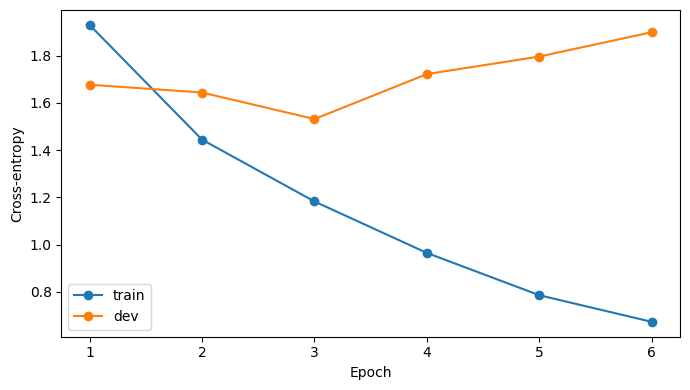

Restored best epoch 3 Macro-F1 0.29962961052998865
Train-derived decoder, dev-selected strength: 1.0 raw Macro-F1: 0.29962961052998865 postprocessed Macro-F1: 0.35180292271854297


In [8]:
model, history, best_path = train_model(model, train_loader, dev_loader, label_names, optimizer, class_weights)
# Learn label transitions using train only; tune the smoothing strength using dev only.
decoder_config = tune_transition_decoder(model, train_records, dev_records, dev_loader, label_to_id)


Raw development metrics: {
  "loss": 1.5313015561533463,
  "macro_f1": 0.29962961052998865,
  "macro_precision": 0.34993922441735437,
  "macro_recall": 0.29900951649635465
}
After optional transition decoding: {
  "macro_f1": 0.35180292271854297,
  "macro_precision": 0.41151550435500917,
  "macro_recall": 0.37447176712189795
}
                        precision    recall  f1-score   support

                  Fact       0.72      0.38      0.50       444
                 Issue       0.00      0.00      0.00        15
    ArgumentPetitioner       0.62      0.81      0.70       400
    ArgumentRespondent       0.89      0.46      0.60       272
               Statute       0.65      0.74      0.69       120
               Dissent       0.00      0.00      0.00         0
   PrecedentReliedUpon       0.44      0.24      0.31       254
PrecedentNotReliedUpon       0.11      0.72      0.19        50
    PrecedentOverruled       0.00      0.00      0.00         0
    RulingByLowerCourt       0

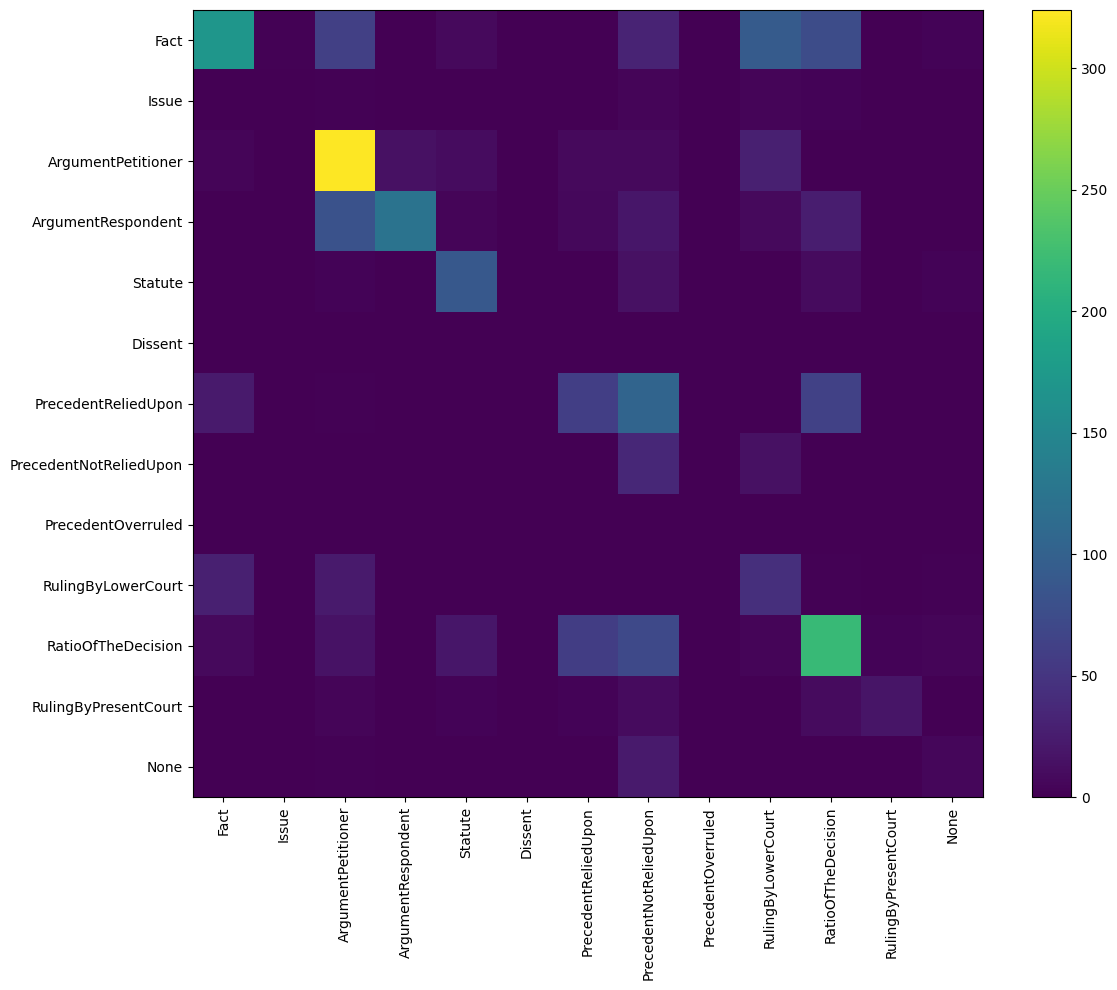

Encoded 1396 sentences; truncated targets: 14
CL raw Macro-F1: 0.28732992401511886
CL development metrics: {
  "macro_f1": 0.42773363209949744,
  "macro_precision": 0.4859659132711015,
  "macro_recall": 0.4053718336217115
}
Encoded 746 sentences; truncated targets: 12
IT raw Macro-F1: 0.2576073960465673
IT development metrics: {
  "macro_f1": 0.2057495864670767,
  "macro_precision": 0.3567722751242203,
  "macro_recall": 0.2362251678267429
}


In [9]:
raw_metrics, _, _ = evaluate(model, dev_loader, len(label_names))
metrics, gold, pred = evaluate_decoded(model, dev_records, dev_loader, len(label_names), decoder_config)
print('Raw development metrics:', json.dumps(raw_metrics, indent=2))
print('After optional transition decoding:', json.dumps(metrics, indent=2))
print(classification_report(gold, pred, labels=list(range(len(label_names))), target_names=label_names, zero_division=0))
with open(OUTPUT_DIR / 'dev_report.txt', 'w', encoding='utf-8') as f:
    f.write(classification_report(gold, pred, labels=list(range(len(label_names))), target_names=label_names, zero_division=0))
cm = confusion_matrix(gold, pred, labels=list(range(len(label_names))))
plt.figure(figsize=(12, 10))
plt.imshow(cm, aspect='auto')
plt.xticks(range(len(label_names)), label_names, rotation=90)
plt.yticks(range(len(label_names)), label_names)
plt.colorbar()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'dev_confusion_matrix.png', dpi=150)
plt.show()


# Domain-specific diagnostics (checkpoint selection still uses the combined dev set).
for domain_name, domain_rows in [('CL', data['CL_dev']), ('IT', data['IT_dev'])]:
    domain_records = records_from_payload(domain_rows, True, domain_name)
    domain_loader = make_loader(domain_records, tokenizer, label_to_id, labeled=True, shuffle=False)
    domain_raw, _, _ = evaluate(model, domain_loader, len(label_names))
    domain_metrics, domain_gold, domain_pred = evaluate_decoded(model, domain_records, domain_loader, len(label_names), decoder_config)
    print(f'{domain_name} raw Macro-F1:', domain_raw['macro_f1'])
    print(f'{domain_name} development metrics:', json.dumps(domain_metrics, indent=2))
    with open(OUTPUT_DIR / f'{domain_name.lower()}_dev_report.txt', 'w', encoding='utf-8') as f:
        f.write(classification_report(domain_gold, domain_pred, labels=list(range(len(label_names))), target_names=label_names, zero_division=0))


## 6. Generate test prediction JSON

Output maps each document ID to ordered official label strings, one per sentence.

In [10]:
pred_path = save_predictions(model, test_records, label_names, label_to_id, 'model4_full_finetuning', decoder_config)
print('Prediction JSON:', pred_path)


Encoded 2197 sentences; truncated targets: 30
Predicted documents: 10 sentences: 2197
Prediction JSON: /kaggle/working/phase3_rr/model4_full_finetuning_prediction.json


## Validation notes

- Exact Model 4 Phase-1 backbone layers and custom tokenizer are preserved; checkpoint loads with `strict=True`.
- Corrected the undefined previous-sentence-context variable, improved mixed-precision stability, cached BPE encodings, length-bucketed batches, and added balanced loss, sequence-aware pooling, document-position/domain features, warmup/cosine schedule, and Macro-F1 early stopping.
- Full fine-tuning updates all pretrained backbone weights and trains a newly initialized classification head; gradient accumulation keeps memory usage predictable.
- Optional Viterbi smoothing uses train-only label transitions, with a single strength selected on the development set (zero smoothing if it performs best).
- The dataset must be accessed with your Hugging Face token through Kaggle secrets (`HF`); Phase-1 tokenizer and checkpoint must be attached separately.
- **The code is smoke-tested on synthetic inputs only. No real Macro-F1 score or guaranteed improvement is claimed.**
